In [ ]:
# Download and extract dataset
import os, glob

DATA_DIR = "/content/PetImages"

already_ready = (
    os.path.exists(os.path.join(DATA_DIR, "Cat")) and
    os.path.exists(os.path.join(DATA_DIR, "Dog")) and
    len(glob.glob(os.path.join(DATA_DIR, "Cat", "*.jpg"))) > 1000
)

if already_ready:
    print(f"Dataset already present")
    cat_count = len(glob.glob(os.path.join(DATA_DIR, 'Cat', '*.jpg')))
    dog_count = len(glob.glob(os.path.join(DATA_DIR, 'Dog', '*.jpg')))
    print(f"Cat images: {cat_count}")
    print(f"Dog images: {dog_count}")
else:
    print("Downloading Microsoft Cats & Dogs dataset")
    URL = "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip"
    !wget --no-check-certificate -q {URL} -O /content/cats_and_dogs.zip
    print("Extracting archive ...")
    !unzip -q -o /content/cats_and_dogs.zip -d /content/
    !rm -f /content/cats_and_dogs.zip
    cat_count = len(glob.glob(os.path.join(DATA_DIR, 'Cat', '*.jpg')))
    dog_count = len(glob.glob(os.path.join(DATA_DIR, 'Dog', '*.jpg')))
    print(f"Done!  Cat images: {cat_count} | Dog images: {dog_count}")

In [ ]:
# Setup & imports
import os
import glob
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "/content/PetImages"

print(f"TensorFlow Version  : {tf.__version__}")
print(f"GPU Devices detected: {tf.config.list_physical_devices('GPU')}")

In [ ]:
# Index dataset paths and labels
cat_paths = [
    p for p in glob.glob(os.path.join(DATA_DIR, "Cat", "*"))
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
]
dog_paths = [
    p for p in glob.glob(os.path.join(DATA_DIR, "Dog", "*"))
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
]

records = []
for fpath in tqdm(cat_paths + dog_paths, desc="Indexing images"):
    parent_folder = os.path.basename(os.path.dirname(fpath))
    label = "dog" if parent_folder == "Dog" else "cat"
    records.append({
        "filepath": fpath,
        "filename": os.path.basename(fpath),
        "label": label
    })

df = pd.DataFrame(records, columns=["filepath", "filename", "label"])

print(f"Total images found: {len(df)}")
print(df["label"].value_counts())
df.head()

## Data Integrity & Cleaning

In [ ]:
# Check image integrity and remove corrupted files
def clean_and_verify(dataframe):
    valid_indices = []
    corrupted_files = []

    print(f"Verifying integrity of {len(dataframe)} images...")
    for idx, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc="Verifying images"):
        fpath = row["filepath"]

        # Check size > 0
        if not os.path.isfile(fpath) or os.path.getsize(fpath) == 0:
            corrupted_files.append((fpath, "Zero byte / missing"))
            continue

        # Test header and decode
        try:
            with Image.open(fpath) as img:
                img.verify()
            with Image.open(fpath) as img:
                img.convert("RGB")
            valid_indices.append(idx)
        except (UnidentifiedImageError, OSError, SyntaxError) as e:
            corrupted_files.append((fpath, str(e)))

    clean_df = dataframe.loc[valid_indices].reset_index(drop=True)

    print("\nCleaning Report")
    print(f"Valid images: {len(clean_df)}")
    print(f"Corrupted files : {len(corrupted_files)}")
    if corrupted_files:
        print("  Corrupt samples :", corrupted_files[:5])

    return clean_df, corrupted_files

clean_df, corrupted = clean_and_verify(df)

In [ ]:
# Preview some images
sample_df = pd.concat([
    clean_df[clean_df["label"] == "cat"].sample(5, random_state=SEED),
    clean_df[clean_df["label"] == "dog"].sample(5, random_state=SEED)
])

plt.figure(figsize=(15, 6))
for i, (_, row) in enumerate(sample_df.iterrows()):
    plt.subplot(2, 5, i + 1)
    img = Image.open(row["filepath"])
    plt.imshow(img)
    plt.title(f"{row['label'].upper()} ({img.size[0]}x{img.size[1]})")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Dataset Split (70 / 15 / 15)

In [ ]:
from sklearn.model_selection import train_test_split

clean_df['label_idx'] = clean_df['label'].map({'cat': 0, 'dog': 1})

# Train / Temp split (70/30)
train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=SEED,
    stratify=clean_df['label_idx']
)

# Val / Test split (15/15)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df['label_idx']
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test', 'Total'],
    'Total Samples': [len(train_df), len(val_df), len(test_df), len(clean_df)],
    'Cats': [
        (train_df['label_idx'] == 0).sum(),
        (val_df['label_idx'] == 0).sum(),
        (test_df['label_idx'] == 0).sum(),
        (clean_df['label_idx'] == 0).sum()
    ],
    'Dogs': [
        (train_df['label_idx'] == 1).sum(),
        (val_df['label_idx'] == 1).sum(),
        (test_df['label_idx'] == 1).sum(),
        (clean_df['label_idx'] == 1).sum()
    ],
    'Percentage': [
        f"{len(train_df)/len(clean_df):.1%}",
        f"{len(val_df)/len(clean_df):.1%}",
        f"{len(test_df)/len(clean_df):.1%}",
        "100.0%"
    ]
})

print("Dataset Split Summary:")
print(split_summary)

In [ ]:
# tf.data pipeline
from PIL import Image
import numpy as np

IMG_HEIGHT, IMG_WIDTH = 150, 150
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def _load_image_with_pil(filepath_tensor):
    """Load and resize image with PIL."""
    filepath = filepath_tensor.numpy().decode("utf-8")
    img = Image.open(filepath).convert("RGB")
    img = img.resize((IMG_WIDTH, IMG_HEIGHT))
    return np.array(img, dtype=np.float32)

def load_and_preprocess_image(filepath, label):
    img = tf.py_function(
        func=_load_image_with_pil,
        inp=[filepath],
        Tout=tf.float32
    )
    img = tf.ensure_shape(img, [IMG_HEIGHT, IMG_WIDTH, 3])
    return img, label

def create_dataset(dataframe, is_training=False):
    filepaths = dataframe['filepath'].values
    labels = dataframe['label_idx'].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    if is_training:
        ds = ds.shuffle(buffer_size=min(len(dataframe), 5000), seed=SEED)

    ds = ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

# Build datasets
train_ds = create_dataset(train_df, is_training=True)
val_ds   = create_dataset(val_df, is_training=False)
test_ds  = create_dataset(test_df, is_training=False)

print(f"Train batches: {len(train_ds)}")
print(f"Val batches  : {len(val_ds)}")
print(f"Test batches : {len(test_ds)}")

In [ ]:
# Inspect sample batch
for images, labels in train_ds.take(1):
    print(f"Batch image shape: {images.shape}")
    print(f"Batch label shape: {labels.shape}")

    plt.figure(figsize=(12, 6))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        lbl = "Dog" if labels[i].numpy() == 1.0 else "Cat"
        plt.title(f"{lbl} ({labels[i].numpy():.0f})")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
def build_cnn():
    # Input
    inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3), name="input_image")

    # Data augmentation
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)

    # Rescaling
    x = layers.Rescaling(1.0 / 255.0)(x)

    # Conv Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)

    # Conv Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)

    # Conv Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)

    # Conv Block 4
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)

    # Classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output_prediction")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="CatDog_CNN")
    return model

model = build_cnn()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

model.summary()

In [ ]:
# Checkpoint setup and training
import os
import pandas as pd
from tensorflow import keras
from tensorflow.keras import callbacks

# Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    CHECKPOINT_DIR = '/content/drive/MyDrive/cat_dog_cnn'
except Exception as e:
    print(f"Drive mount note: {e}")
    CHECKPOINT_DIR = './cat_dog_checkpoints'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'latest_cat_dog_cnn.keras')
BEST_CHECKPOINT_PATH   = os.path.join(CHECKPOINT_DIR, 'best_cat_dog_cnn.keras')
CSV_LOG_PATH           = os.path.join(CHECKPOINT_DIR, 'training_log.csv')

EPOCHS = 30
RESUME_TRAINING = True

initial_epoch = 0
best_val_acc = None

# Auto resume from checkpoint and csv logging
if RESUME_TRAINING:
    if os.path.exists(LATEST_CHECKPOINT_PATH) and os.path.exists(CSV_LOG_PATH):
        try:
            log_df = pd.read_csv(CSV_LOG_PATH)
            if not log_df.empty and 'epoch' in log_df.columns:
                completed_epochs = int(log_df['epoch'].iloc[-1]) + 1
                if completed_epochs < EPOCHS:
                    print(f"\nFOUND EXISTING TRAINING STATE ")
                    print(f"Resuming from epoch {completed_epochs + 1}/{EPOCHS} (completed: {completed_epochs} epochs).")
                    model = keras.models.load_model(LATEST_CHECKPOINT_PATH)
                    initial_epoch = completed_epochs
                    if 'val_accuracy' in log_df.columns:
                        best_val_acc = float(log_df['val_accuracy'].max())
                        print(f"Previous best validation accuracy: {best_val_acc:.4f}")
        except Exception as e:
            print(f"Warning loading latest checkpoint ({e}).")

    # 2. Fallback: load weights from best model
    if initial_epoch == 0 and os.path.exists(BEST_CHECKPOINT_PATH):
        try:
            print(f"\n>>> FOUND PREVIOUS SAVED MODEL: {BEST_CHECKPOINT_PATH} <<<")
            print("Loading weights and optimizer state from best_cat_dog_cnn.keras...")
            model = keras.models.load_model(BEST_CHECKPOINT_PATH)
            if hasattr(model.optimizer, 'iterations'):
                total_steps = int(model.optimizer.iterations.numpy())
                steps_per_epoch = len(train_ds)
                recovered_epochs = total_steps // steps_per_epoch
                if recovered_epochs > 0:
                    initial_epoch = min(recovered_epochs, EPOCHS - 1)
                    print(f"Detected {total_steps} completed training steps ({steps_per_epoch} steps/epoch).")
                    print(f"Successfully recovered! Resuming from epoch {initial_epoch + 1}/{EPOCHS}.")
                else:
                    print(f"Loaded weights ({total_steps} steps). Continuing training...")
                    initial_epoch = 1
            else:
                initial_epoch = 1
        except Exception as e:
            print(f"Fallback load warning ({e}). Starting from epoch 1.")

# Callbacks
best_checkpoint_kwargs = {
    'filepath': BEST_CHECKPOINT_PATH,
    'monitor': 'val_accuracy',
    'mode': 'max',
    'save_best_only': True,
    'verbose': 1
}
if best_val_acc is not None:
    best_checkpoint_kwargs['initial_value_threshold'] = best_val_acc

training_callbacks = [
    callbacks.ModelCheckpoint(
        filepath=LATEST_CHECKPOINT_PATH,
        save_best_only=False,
        verbose=1
    ),
    callbacks.ModelCheckpoint(**best_checkpoint_kwargs),
    callbacks.CSVLogger(CSV_LOG_PATH, append=True),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

# Train
if initial_epoch < EPOCHS:
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        initial_epoch=initial_epoch,
        callbacks=training_callbacks,
        verbose=1
    )
else:
    print(f"All {EPOCHS} epochs completed! Best model is saved at: {BEST_CHECKPOINT_PATH}")

In [ ]:
history_dict = history.history
epochs_range = range(1, len(history_dict['loss']) + 1)

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_dict['loss'], 'b-o', label='Training Loss')
plt.plot(epochs_range, history_dict['val_loss'], 'r-s', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_dict['accuracy'], 'b-o', label='Training Accuracy')
plt.plot(epochs_range, history_dict['val_accuracy'], 'r-s', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

,epoch,accuracy,auc,loss,val_accuracy,val_auc,val_loss
0,11,0.8576,0.9295,0.3384,0.8355,0.9407,0.3799
1,12,0.8628,0.9359,0.3235,0.8125,0.9479,0.4187
2,13,0.8657,0.9387,0.3160,0.8347,0.9457,0.3801
3,14,0.8655,0.9405,0.3124,0.8475,0.9504,0.3256
4,15,0.8707,0.9429,0.3055,0.8248,0.9468,0.3842
5,16,0.8713,0.9433,0.3046,0.8213,0.9540,0.3756
6,17,0.8828,0.9525,0.2794,0.8864,0.9570,0.2672
7,18,0.8776,0.9510,0.2840,0.8829,0.9598,0.2653
8,19,0.8864,0.9562,0.2692,0.8869,0.9573,0.2687
9,20,0.8923,0.9575,0.2644,0.8808,0.9561,0.2731


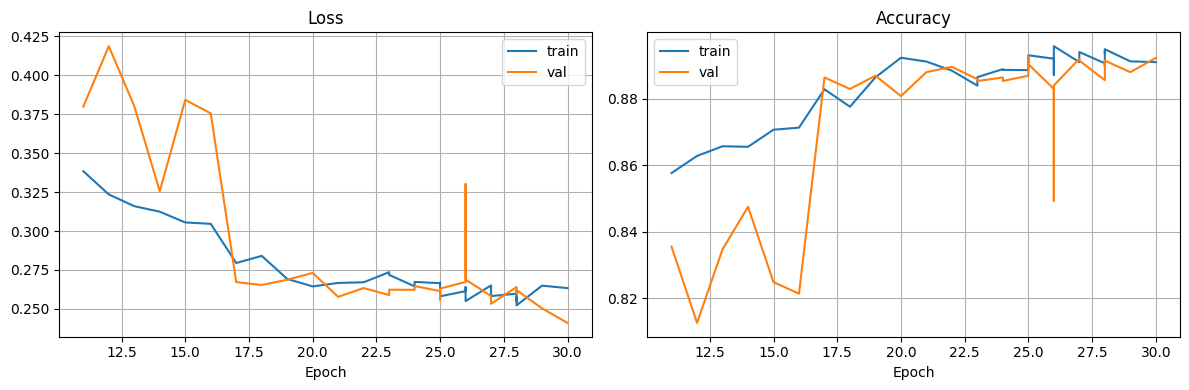

In [26]:
#view training logs
df = pd.read_csv(CSV_LOG_PATH)
df['epoch'] = df['epoch'] + 1
display(df)

# Plot loss and accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df['epoch'], df['loss'], label='train')
plt.plot(df['epoch'], df['val_loss'], label='val')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(df['epoch'], df['accuracy'], label='train')
plt.plot(df['epoch'], df['val_accuracy'], label='val')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Testing Best Model on test set

In [27]:
# Load best model
best_model = keras.models.load_model(BEST_CHECKPOINT_PATH)
best_model.summary()

# Evaluate on test set
results = best_model.evaluate(test_ds)
for name, val in zip(best_model.metrics_names, results):
    print(f'{name}: {val:.4f}')


Model: "CatDog_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 774,181 (2.95 MB)

 Trainable params: 257,825 (1007.13 KB)

 Non-trainable params: 704 (2.75 KB)

 Optimizer params: 515,652 (1.97 MB)

118/118 ━━━━━━━━━━━━━━━━━━━━ 72s 607ms/step - accuracy: 0.9037 - auc: 0.9661 - loss: 0.2372
loss: 0.2372
compile_metrics: 0.9037


Metrics

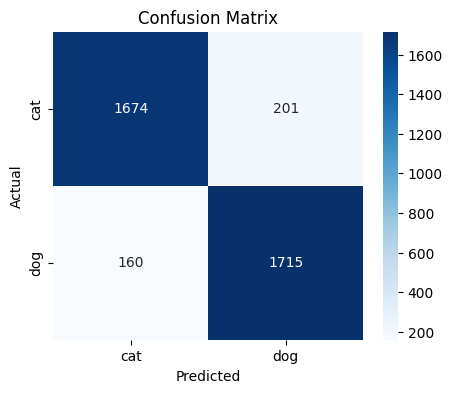

              precision    recall  f1-score   support

         cat       0.91      0.89      0.90      1875
         dog       0.90      0.91      0.90      1875

    accuracy                           0.90      3750
   macro avg       0.90      0.90      0.90      3750
weighted avg       0.90      0.90      0.90      3750



In [28]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true, y_pred = [], []
for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0).flatten()
    y_pred.extend((preds >= 0.5).astype(int))
    y_true.extend(labels.numpy().astype(int))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['cat', 'dog'], yticklabels=['cat', 'dog'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=['cat', 'dog']))


In [32]:
# Save final model
best_model.save('best_cat_dog_cnn.keras')
try:
    from google.colab import files
    files.download('best_cat_dog_cnn.keras')
except ImportError:
    print("Saved locally as best_cat_dog_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>